# Pair 2: Product photo editing, Qwen-Image-2.1 (System A) vs FLUX.2 [klein] 4B (System B)

Our content team pays an agency for routine edits of supplier photos: new backgrounds, colour variants and sale tags.
An editing model is only useful if it follows the instruction and leaves the product itself alone, because a photo that
does not match the real item is misleading under the Australian Consumer Law.

- System A, Qwen-Image-2.1 (Qwen team, 2026): 7B multimodal diffusion transformer, 40 sampling steps.
- System B, FLUX.2 [klein] 4B (Black Forest Labs, 2026): rectified-flow transformer distilled to 4 steps.

8 edits (4 product photos x 2 tasks, every task twice), each with seeds 0, 1 and 2. I measure instruction following
(CLIP direction), product preservation on the product region (DINOv2, LPIPS, SSIM), the sale-tag text with OCR, speed
and a simple cost comparison.

To run on Kaggle: GPU T4 x2, Internet on, then Save & Run All (about 75 min, Qwen takes about 2 min per edit).

## Setup
Install the pinned packages, import the libraries and define the four editing tasks and their instructions.

In [ ]:
# install the pinned versions used for this run
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], capture_output=True)   # clashes with diffusers 0.41
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers==0.41.0", "transformers==5.20.1", "accelerate==1.15.0",
                "bitsandbytes==0.50.2", "pyiqa==0.1.16", "easyocr==1.7.2", "sentencepiece"], check=True, capture_output=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'diffusers==0.41.0', 'transformers==5.20.1', 'accelerate==1.15.0', 'bitsandbytes==0.50.2', 'pyiqa==0.1.16', 'easyocr==1.7.2', 'sentencepiece'], returncode=0, stdout=b'', stderr=b"ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.\ngradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.\n")

In [ ]:
# libraries
import csv, gzip, json, os, random, re, shutil, time, urllib.request
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy import ndimage
from scipy.stats import wilcoxon

# output folder, system names, seeds and edit size
OUT = Path("/kaggle/working/pair2")
OUT.mkdir(parents=True, exist_ok=True)
A, B = "Qwen-Image-2.1", "FLUX.2 klein"
SEEDS = [0, 1, 2]
SIZE = 768                 # both edit at about 768 x 768
TASKS = {   # instruction, and the target caption used by the CLIP direction score
    "studio_background": ("Replace the background with a light grey studio backdrop and a soft shadow under the {p}. Do not change the {p}.",
                          "a studio photo of a {p} on a light grey backdrop with a soft shadow"),
    "lifestyle_background": ("Place the {p} in a bright, modern living room with soft natural light. Keep the {p} exactly as it is.",
                             "a photo of a {p} in a bright modern living room"),
    "colour_variant": ("Change the colour of the {p} to navy blue. Keep its shape, texture and every other detail identical.",
                       "a photo of a navy blue {p} on a white background"),
    "sale_tag": ("Add a small red tag that says 'SALE 20% OFF' in the top-left corner. Do not change anything else.",
                 "a photo of a {p} with a red tag saying SALE 20% OFF in the corner"),
}
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print(torch.cuda.get_device_name(0))

Tesla T4


## Data
Real catalogue photos from Amazon Berkeley Objects (Collins et al., 2022; CC BY 4.0, "Amazon Berkeley Objects,
Amazon.com"). Products are picked at random (seed 0) across product types, and only clean shots on a white background
are kept so the product can be cut out for scoring. The source URL of every photo goes into `products.csv`.

In [ ]:
# download helpers for Amazon Berkeley Objects (ABO)
ABO = "https://amazon-berkeley-objects.s3.amazonaws.com"
CACHE = Path("/tmp/abo")


def download(url, dest):
    dest = Path(dest)
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(url, timeout=120) as r:
            dest.write_bytes(r.read())
    return dest


def product_mask(img):
    # product = everything that isn't the white background touching the border
    labels, _ = ndimage.label(np.asarray(img.convert("RGB")).min(axis=2) >= 240)
    border = np.unique(np.r_[labels[0], labels[-1], labels[:, 0], labels[:, -1]])
    return ndimage.binary_fill_holes(ndimage.binary_opening(~np.isin(labels, border[border > 0]), iterations=2))


# read the ABO listings (English product names) and the image index
listings = []
for shard in "0123":
    with gzip.open(download(f"{ABO}/listings/metadata/listings_{shard}.json.gz", CACHE / f"l{shard}.json.gz"), "rt") as f:
        for line in f:
            d = json.loads(line)
            name = next((x["value"] for x in d.get("item_name", []) if x.get("language_tag", "").startswith("en")), None)
            if name and d.get("main_image_id"):
                ptype = d["product_type"][0]["value"] if d.get("product_type") else "product"
                listings.append((d["item_id"], name, ptype, d["main_image_id"]))
with gzip.open(download(f"{ABO}/images/metadata/images.csv.gz", CACHE / "images.csv.gz"), "rt") as f:
    image_info = {r["image_id"]: r for r in csv.DictReader(f)}

# one product per product type, in a random order, so the set is mixed
by_type = {}
for item in listings:
    info = image_info.get(item[3])
    if info and min(int(info["width"]), int(info["height"])) >= 800:
        by_type.setdefault(item[2], []).append((*item, info["path"]))
types = sorted(by_type)
random.Random(0).shuffle(types)

# keep the first 4 clean white-background photos, shrink them to 1024 px and record their source URLs
products = []
for t in types:
    item_id, name, ptype, _, path = random.Random(0).choice(by_type[t])
    url = f"{ABO}/images/original/{path}"
    img = Image.open(download(url, CACHE / "photos" / Path(path).name)).convert("RGB")
    m = product_mask(img.resize((256, round(256 * img.height / img.width))))
    if not (0.05 < m.mean() < 0.85 and np.r_[m[0], m[-1], m[:, 0], m[:, -1]].mean() < 0.05):
        continue                                   # not a clean shot on white
    img.thumbnail((1024, 1024))
    img.save(CACHE / f"{item_id}.png")
    words = [w.lower() for w in re.findall(r"[A-Za-z]{3,}", name.split(",")[0]) if w.lower() not in ("amazon", "basics", "the", "and", "with", "for")]
    products.append({"item_id": item_id, "product": " ".join(words[-2:]) or ptype.lower(), "type": ptype,
                     "photo": str(CACHE / f"{item_id}.png"), "source_url": url, "licence": "CC BY 4.0, Amazon Berkeley Objects"})
    if len(products) == 4:
        break
products = pd.DataFrame(products)
products.to_csv(OUT / "products.csv", index=False)

# two of the four tasks per photo, rotating, gives 8 edits; same instruction for both editors
task_names = list(TASKS)
edits = pd.DataFrame([{"edit": f"{p.item_id}_{task_names[(2 * i + j) % 4]}", "task": task_names[(2 * i + j) % 4], "photo": p.photo,
                       "instruction": TASKS[task_names[(2 * i + j) % 4]][0].format(p=p.product),
                       "target": TASKS[task_names[(2 * i + j) % 4]][1].format(p=p.product),
                       "source": f"a photo of a {p.product} on a white background"}
                      for i, p in enumerate(products.itertuples()) for j in range(2)])
edits.to_csv(OUT / "edits.csv", index=False)
display(edits[["edit", "task", "instruction"]])

,edit,task,instruction
0,B00JKQKAYG_studio_background,studio_background,Replace the background with a light grey studi...
1,B00JKQKAYG_lifestyle_background,lifestyle_background,"Place the devices pink in a bright, modern liv..."
2,B07FF6ZGH8_colour_variant,colour_variant,Change the colour of the ergonomic backpack to...
3,B07FF6ZGH8_sale_tag,sale_tag,Add a small red tag that says 'SALE 20% OFF' i...
4,B075XVTSPS_studio_background,studio_background,Replace the background with a light grey studi...
5,B075XVTSPS_lifestyle_background,lifestyle_background,"Place the power bank in a bright, modern livin..."
6,B07VXQXBKV_colour_variant,colour_variant,Change the colour of the adapter renewed to na...
7,B07VXQXBKV_sale_tag,sale_tag,Add a small red tag that says 'SALE 20% OFF' i...


## Running the two editors
Same photo, instruction and seed for both, with each model's recommended settings. The T4 has no bfloat16, so both run
in float16; Qwen is quantised to 4-bit (NF4) to fit, and both use CPU offload because the transformer and the text
encoder don't fit in 16 GB together. Each edit prints one line so progress is visible in the log.

In [ ]:
# load the models and run every edit with every seed
import gc
from diffusers import Flux2KleinPipeline, QwenImage21Pipeline
from diffusers.quantizers import PipelineQuantizationConfig
from diffusers.utils import logging as diffusers_logging
from transformers.utils import logging as transformers_logging
for lib in (diffusers_logging, transformers_logging):     # keep the loading output short
    lib.set_verbosity_error()
    lib.disable_progress_bar()


def edit_size(img):
    # about SIZE x SIZE pixels, same shape as the photo, sides a multiple of 32
    w = round((SIZE * SIZE * img.width / img.height) ** 0.5 / 32) * 32
    return w, round(w * img.height / img.width / 32) * 32


# run all edits for one editor and save the output images and timings
def run(system, pipe, folder, **settings):
    rows = []
    for seed in SEEDS:
        (OUT / folder / f"seed{seed}").mkdir(parents=True, exist_ok=True)
        for e in edits.itertuples():
            photo = Image.open(e.photo).convert("RGB")
            w, h = edit_size(photo)
            torch.cuda.synchronize(); t0 = time.time()
            out = pipe(prompt=e.instruction, image=photo.resize((w, h)), width=w, height=h,
                       generator=torch.Generator("cpu").manual_seed(seed), **settings).images[0]
            torch.cuda.synchronize()
            out.save(OUT / folder / f"seed{seed}" / f"{e.edit}.png")
            rows.append({"system": system, "seed": seed, "edit": e.edit, "seconds": time.time() - t0,
                         "output": str(OUT / folder / f"seed{seed}" / f"{e.edit}.png")})
            print(f"{system}, seed {seed}, {e.edit}: {rows[-1]['seconds']:.0f} s", flush=True)
    pd.DataFrame(rows).to_csv(OUT / f"runs_{folder}.csv", index=False)     # saved straight away in case a later step fails
    return rows


# Qwen-Image-2.1: 4-bit NF4 so it fits on the T4's 16 GB, with CPU offload
t0 = time.time()
nf4 = PipelineQuantizationConfig(quant_backend="bitsandbytes_4bit", components_to_quantize=["transformer", "text_encoder"],
                                 quant_kwargs={"load_in_4bit": True, "bnb_4bit_quant_type": "nf4", "bnb_4bit_compute_dtype": torch.float16})
pipe = QwenImage21Pipeline.from_pretrained("Qwen/Qwen-Image-2.1", dtype=torch.float16, quantization_config=nf4)
gc.collect(); torch.cuda.empty_cache()
pipe.enable_model_cpu_offload()
pipe.set_progress_bar_config(disable=True)
print(f"Qwen loaded in {(time.time() - t0) / 60:.1f} min", flush=True)
runs = run(A, pipe, "qwen", num_inference_steps=40, true_cfg_scale=1.0, output_resolution=SIZE)    # model card defaults
del pipe; gc.collect(); torch.cuda.empty_cache()

Qwen loaded in 4.7 min
Qwen-Image-2.1, seed 0, B00JKQKAYG_studio_background: 117 s
Qwen-Image-2.1, seed 0, B00JKQKAYG_lifestyle_background: 115 s
Qwen-Image-2.1, seed 0, B07FF6ZGH8_colour_variant: 114 s
Qwen-Image-2.1, seed 0, B07FF6ZGH8_sale_tag: 115 s
Qwen-Image-2.1, seed 0, B075XVTSPS_studio_background: 115 s
Qwen-Image-2.1, seed 0, B075XVTSPS_lifestyle_background: 115 s
Qwen-Image-2.1, seed 0, B07VXQXBKV_colour_variant: 114 s
Qwen-Image-2.1, seed 0, B07VXQXBKV_sale_tag: 115 s
Qwen-Image-2.1, seed 1, B00JKQKAYG_studio_background: 113 s
Qwen-Image-2.1, seed 1, B00JKQKAYG_lifestyle_background: 113 s
Qwen-Image-2.1, seed 1, B07FF6ZGH8_colour_variant: 115 s
Qwen-Image-2.1, seed 1, B07FF6ZGH8_sale_tag: 115 s
Qwen-Image-2.1, seed 1, B075XVTSPS_studio_background: 114 s
Qwen-Image-2.1, seed 1, B075XVTSPS_lifestyle_background: 115 s
Qwen-Image-2.1, seed 1, B07VXQXBKV_colour_variant: 114 s
Qwen-Image-2.1, seed 1, B07VXQXBKV_sale_tag: 114 s
Qwen-Image-2.1, seed 2, B00JKQKAYG_studio_background:

In [ ]:
# FLUX.2 [klein] 4B, loaded after Qwen is cleared from the GPU
t0 = time.time()
pipe = Flux2KleinPipeline.from_pretrained("black-forest-labs/FLUX.2-klein-4B", dtype=torch.float16)
pipe.enable_model_cpu_offload()
pipe.set_progress_bar_config(disable=True)
print(f"klein loaded in {(time.time() - t0) / 60:.1f} min", flush=True)
runs += run(B, pipe, "klein", num_inference_steps=4, guidance_scale=1.0)    # distilled: 4 steps, no guidance
del pipe; gc.collect(); torch.cuda.empty_cache()

klein loaded in 2.3 min
FLUX.2 klein, seed 0, B00JKQKAYG_studio_background: 28 s
FLUX.2 klein, seed 0, B00JKQKAYG_lifestyle_background: 27 s
FLUX.2 klein, seed 0, B07FF6ZGH8_colour_variant: 27 s
FLUX.2 klein, seed 0, B07FF6ZGH8_sale_tag: 27 s
FLUX.2 klein, seed 0, B075XVTSPS_studio_background: 27 s
FLUX.2 klein, seed 0, B075XVTSPS_lifestyle_background: 27 s
FLUX.2 klein, seed 0, B07VXQXBKV_colour_variant: 27 s
FLUX.2 klein, seed 0, B07VXQXBKV_sale_tag: 27 s
FLUX.2 klein, seed 1, B00JKQKAYG_studio_background: 27 s
FLUX.2 klein, seed 1, B00JKQKAYG_lifestyle_background: 27 s
FLUX.2 klein, seed 1, B07FF6ZGH8_colour_variant: 27 s
FLUX.2 klein, seed 1, B07FF6ZGH8_sale_tag: 27 s
FLUX.2 klein, seed 1, B075XVTSPS_studio_background: 27 s
FLUX.2 klein, seed 1, B075XVTSPS_lifestyle_background: 27 s
FLUX.2 klein, seed 1, B07VXQXBKV_colour_variant: 27 s
FLUX.2 klein, seed 1, B07VXQXBKV_sale_tag: 27 s
FLUX.2 klein, seed 2, B00JKQKAYG_studio_background: 27 s
FLUX.2 klein, seed 2, B00JKQKAYG_lifestyle_

In [ ]:
# median seconds per edit, by editor and seed
runs = pd.DataFrame(runs).merge(edits, on="edit")
display(runs.groupby(["system", "seed"]).seconds.median().unstack().round(1))

seed,0,1,2
system,,,
FLUX.2 klein,27.0,26.9,26.9
Qwen-Image-2.1,114.9,114.4,114.5


## Metrics
Input and output are compared at the same size (long side 512). The product region comes from the white catalogue
background, so a new background doesn't count as damage.
- clip_dir: CLIP directional similarity, did the image change in the direction the text asked for?
- product_dino, product_lpips (lower is better), product_ssim: how much the product itself changed. DINOv2 similarity
  is the identity metric used in DreamBooth (week 3).
- ocr_match: how close the OCR'd text is to "SALE 20% OFF" (1 = exact), sale-tag edits only.

The colour edits are supposed to change the product, so they are left out of the preservation comparison.

In [ ]:
%%capture metric_output
# score every edit: CLIP direction (did the edit happen), and DINOv2, LPIPS and SSIM on the product region
from difflib import SequenceMatcher
import easyocr, pyiqa
from skimage.metrics import structural_similarity
from torchvision.transforms.functional import to_tensor
from transformers import AutoImageProcessor, AutoModel, CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-large-patch14").cuda().eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14")
dino = AutoModel.from_pretrained("facebook/dinov2-base").cuda().eval()
dino_proc = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
lpips = pyiqa.create_metric("lpips", device="cuda")
reader = easyocr.Reader(["en"], gpu=True, verbose=False)
unit = lambda x: torch.nn.functional.normalize(getattr(x, "pooler_output", x).float(), dim=-1).cpu().numpy()
letters = lambda t: "".join(c for c in t.upper() if c.isalnum() or c == "%")

# input and output compared at the same size (long side 512); the product region comes from the white background
rows = []
with torch.no_grad():
    for r in runs.itertuples():
        photo = Image.open(r.photo).convert("RGB")
        size = (round(photo.width * 512 / max(photo.size)), round(photo.height * 512 / max(photo.size)))
        inp, out = photo.resize(size), Image.open(r.output).convert("RGB").resize(size)
        ys, xs = np.where(product_mask(inp))
        box = (xs.min(), ys.min(), xs.max() + 1, ys.max() + 1)
        a, b = inp.crop(box), out.crop(box)

        img_emb = unit(clip.get_image_features(**clip_proc(images=[inp, out], return_tensors="pt").to("cuda")))
        txt_emb = unit(clip.get_text_features(**clip_proc(text=[r.source, r.target], return_tensors="pt", padding=True).to("cuda")))
        di, dt = img_emb[1] - img_emb[0], txt_emb[1] - txt_emb[0]
        feats = unit(dino(**dino_proc(images=[a, b], return_tensors="pt").to("cuda")).last_hidden_state[:, 0])
        row = {"system": r.system, "seed": r.seed, "edit": r.edit, "task": r.task, "seconds": r.seconds,
               "clip_dir": float(di @ dt / (np.linalg.norm(di) * np.linalg.norm(dt))),
               "product_dino": float(feats[0] @ feats[1]),
               "product_lpips": float(lpips(to_tensor(b)[None].cuda(), to_tensor(a)[None].cuda())),
               "product_ssim": structural_similarity(np.asarray(a.convert("L")), np.asarray(b.convert("L")))}
        # sale-tag edits: read the tag with OCR and compare it with 'SALE 20% OFF'
        if r.task == "sale_tag":
            text = " ".join(reader.readtext(np.asarray(Image.open(r.output).convert("RGB")), detail=0))
            row["ocr_text"], row["ocr_match"] = text, SequenceMatcher(None, letters(text), letters("SALE 20% OFF")).ratio()
        rows.append(row)
scores = pd.DataFrame(rows)

In [ ]:
# save the metric log and the per-edit scores
(OUT / "metric_log.txt").write_text(metric_output.stdout + metric_output.stderr)
scores.to_csv(OUT / "scores.csv", index=False)
print(len(scores), "edits scored")

48 edits scored


## Results
Every seed separately, then the mean and standard deviation over seeds. The paired test compares the two editors edit by
edit (each edit averaged over the three seeds). With 8 edits only a large, consistent difference can reach p < 0.05,
so a high p means "not shown", not "no difference".

In [ ]:
# results for every seed, then mean and SD over the three seeds
METRICS = ["clip_dir", "product_dino", "product_lpips", "product_ssim"]
by_seed = scores.groupby(["seed", "system"])[METRICS].mean().reset_index()
by_seed.to_csv(OUT / "results_by_seed.csv", index=False)
display(by_seed.round(4))
display(by_seed.groupby("system")[METRICS].agg(["mean", "std"]).round(4))

# paired Wilcoxon test edit by edit (each edit averaged over the three seeds)
avg = scores.groupby(["system", "edit", "task"])[METRICS].mean().reset_index()
paired = []
for metric in METRICS:
    sub = avg if metric == "clip_dir" else avg[avg.task != "colour_variant"]     # colour edits change the product on purpose
    wide = sub.pivot(index="edit", columns="system", values=metric)
    d = wide[A] - wide[B]
    paired.append({"metric": metric, "edits": len(d), A: wide[A].mean(), B: wide[B].mean(), "A minus B": d.mean(),
                   "edits where A is better": ((d < 0) if metric == "product_lpips" else (d > 0)).mean(), "Wilcoxon p": wilcoxon(d).pvalue})
paired = pd.DataFrame(paired)
paired.to_csv(OUT / "paired_test.csv", index=False)
display(paired.round(4))

,seed,system,clip_dir,product_dino,product_lpips,product_ssim
0,0,FLUX.2 klein,0.1087,0.8098,0.3031,0.8040
1,0,Qwen-Image-2.1,0.1396,0.8886,0.2963,0.7339
2,1,FLUX.2 klein,0.1168,0.8910,0.2976,0.7913
3,1,Qwen-Image-2.1,0.1079,0.8983,0.2932,0.7601
4,2,FLUX.2 klein,0.1194,0.8775,0.2976,0.8060
5,2,Qwen-Image-2.1,0.1403,0.8887,0.2986,0.7838


clip_dir         product_dino         product_lpips         product_ssim        
                   mean     std         mean     std          mean     std         mean     std
system                                                                                         
FLUX.2 klein     0.1149  0.0056       0.8594  0.0435        0.2994  0.0032       0.8004  0.0079
Qwen-Image-2.1   0.1293  0.0185       0.8919  0.0056        0.2960  0.0027       0.7593  0.0250

,metric,edits,Qwen-Image-2.1,FLUX.2 klein,A minus B,edits where A is better,Wilcoxon p
0,clip_dir,8,0.1293,0.1149,0.0144,0.7500,0.1484
1,product_dino,6,0.8742,0.8283,0.0459,0.3333,1.0000
2,product_lpips,6,0.3007,0.2994,0.0013,0.5000,1.0000
3,product_ssim,6,0.7378,0.8037,-0.0659,0.0000,0.0312


## By task, and the sale-tag text

In [ ]:
# scores by task, and the OCR text of every sale tag
by_task = scores.groupby(["task", "system"])[METRICS].mean().round(4)
by_task.to_csv(OUT / "by_task.csv")
display(by_task)
tags = scores[scores.task == "sale_tag"][["system", "seed", "edit", "ocr_text", "ocr_match"]]
tags.to_csv(OUT / "sale_tag_ocr.csv", index=False)
display(tags.round(3))
display(tags.groupby("system").ocr_match.agg(["mean", lambda x: int((x == 1).sum())]).set_axis(["mean match", "exact"], axis=1).round(3))

clip_dir  product_dino  product_lpips  product_ssim
task                 system                                                             
colour_variant       FLUX.2 klein      0.1778        0.9529         0.2994        0.7907
                     Qwen-Image-2.1    0.1875        0.9449         0.2819        0.8238
lifestyle_background FLUX.2 klein      0.1176        0.5186         0.7276        0.5300
                     Qwen-Image-2.1    0.1261        0.6901         0.6997        0.4738
sale_tag             FLUX.2 klein      0.1811        0.9960         0.0275        0.9766
                     Qwen-Image-2.1    0.1798        0.9847         0.0648        0.9144
studio_background    FLUX.2 klein     -0.0167        0.9703         0.1431        0.9044
                     Qwen-Image-2.1    0.0238        0.9478         0.1378        0.8251

,system,seed,edit,ocr_text,ocr_match
3,Qwen-Image-2.1,0,B07FF6ZGH8_sale_tag,"MTy SALE NIH""",0.400
7,Qwen-Image-2.1,0,B07VXQXBKV_sale_tag,SALE 20% OFF POCNv amazon basics,0.541
11,Qwen-Image-2.1,1,B07FF6ZGH8_sale_tag,SALE 20% OFF,1.000
15,Qwen-Image-2.1,1,B07VXQXBKV_sale_tag,Ocwv 20% SALE OFF amazon basics,0.389
19,Qwen-Image-2.1,2,B07FF6ZGH8_sale_tag,20% SALE OFF,0.700
23,Qwen-Image-2.1,2,B07VXQXBKV_sale_tag,SALE 203 OFF % Ocwv C0 amazon pasics,0.462
27,FLUX.2 klein,0,B07FF6ZGH8_sale_tag,3 8 20%,0.400
31,FLUX.2 klein,0,B07VXQXBKV_sale_tag,SALE ZOOFF Oc5v C0 205 OFF amazon basics,0.326
35,FLUX.2 klein,1,B07FF6ZGH8_sale_tag,SALE 20% OFF,1.000
39,FLUX.2 klein,1,B07VXQXBKV_sale_tag,20 Ocwv 7c0 SALE )%FF amazonics,0.400


,mean match,exact
system,,
FLUX.2 klein,0.616,2
Qwen-Image-2.1,0.582,1


## Speed and cost
The agency charges AUD 17.32 per edit (US$12, the low end for compositing work, Racklify; at 0.6928 USD per AUD). The
model's cost is GPU time (AWS g4dn.xlarge with one T4, Sydney, AUD 0.99 per hour) plus a person approving every edit at
AUD 61.41 per hour (ABS average weekly ordinary time earnings, May 2026, over 38 hours, plus 12% super). The approval
time is my own, measured while rating (below); until then 60 s is used. Energy uses the T4's 70 W limit, an upper bound.

In [ ]:
# review time: 60 s unless the ratings sheet already has my timings; during the Kaggle run it did not,
# so this table uses 60 s and the last cell redoes the cost with my measured time
review_s = 60
ratings_file = OUT / "rating" / "my_ratings.csv"
if ratings_file.exists() and pd.read_csv(ratings_file).seconds_to_check.notna().all():
    review_s = pd.read_csv(ratings_file).seconds_to_check.mean()

# cost per edit: GPU time on an AWS g4dn.xlarge (AUD 0.99/h) plus a person's review, against the agency price
cost = []
for system, g in scores.groupby("system"):
    s = g.seconds.median()
    cost.append({"system": system, "seconds per edit": s, "GPU energy Wh per edit (max)": s * 70 / 3600,
                 "GPU AUD per edit": s / 3600 * 0.99, "review AUD per edit": review_s / 3600 * 61.41,
                 "agency AUD per edit": 17.32,
                 "saving AUD per month (2,000 edits)": (17.32 - s / 3600 * 0.99 - review_s / 3600 * 61.41) * 2000})
cost = pd.DataFrame(cost)
cost.to_csv(OUT / "speed_cost.csv", index=False)
display(cost.round(3))

,system,seconds per edit,GPU energy Wh per edit (max),GPU AUD per edit,review AUD per edit,agency AUD per edit,"saving AUD per month (2,000 edits)"
0,FLUX.2 klein,26.897,0.523,0.007,1.023,17.32,32578.206
1,Qwen-Image-2.1,114.677,2.230,0.032,1.023,17.32,32529.927


## Go/no-go
My criteria for using an editor in production: product SSIM of at least 0.70 on the non-colour edits, sale-tag OCR
match of at least 0.90, and at most 60 s per edit on a T4.

In [ ]:
# my go/no-go criteria for production use
keep = scores[scores.task != "colour_variant"]
s = pd.DataFrame({"product SSIM": keep.groupby("system").product_ssim.mean(),
                  "OCR match": tags.groupby("system").ocr_match.mean(),
                  "seconds per edit": scores.groupby("system").seconds.median()})
s["SSIM >= 0.70"] = s["product SSIM"] >= 0.70
s["OCR >= 0.90"] = s["OCR match"] >= 0.90
s["<= 60 s"] = s["seconds per edit"] <= 60
s.to_csv(OUT / "go_no_go.csv")
display(s.round(4))

,product SSIM,OCR match,seconds per edit,SSIM >= 0.70,OCR >= 0.90,<= 60 s
system,,,,,,
FLUX.2 klein,0.8037,0.6162,26.8973,True,False,True
Qwen-Image-2.1,0.7378,0.5818,114.6774,True,False,False


## Governance and risk

| Risk | Control | Owner |
|---|---|---|
| Qwen-Image-2.1 is under the Qwen Research License (no commercial use without an agreement); FLUX.2 klein is Apache 2.0 | No Qwen deployment without a written commercial licence | Head of legal |
| An edit changes the product's shape, logo or colour (Australian Consumer Law s 18 and s 29) | A person approves every edit; product SSIM below 0.70 is rejected automatically | Content team lead |
| Generated sale text is misspelt or shows a wrong price | Prices and sale tags are web overlays, never generated into the image | E-commerce manager |
| Customers can't tell an image was edited by AI | Keep the original; tag edited images in their metadata (C2PA) | Content team lead |
| Off-brand or harmful output (open models have few built-in filters) | Prompts only from fixed templates; every output reviewed | Brand manager |


## Figures
The metric bar chart and every edit (seed 0) next to its input photo (both saved to the results folder).

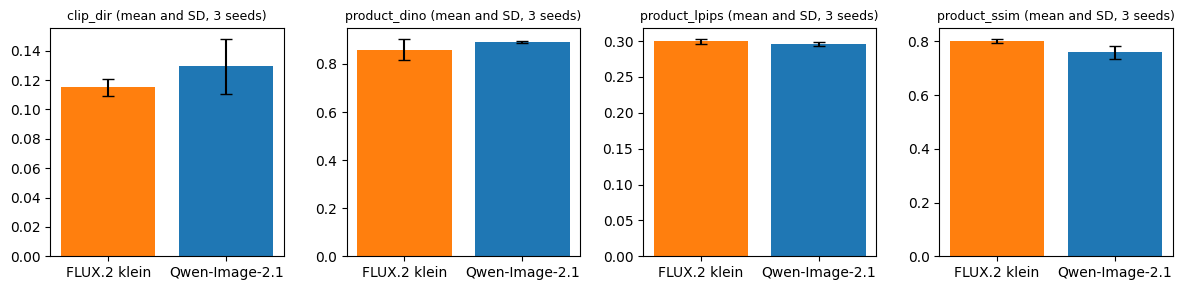

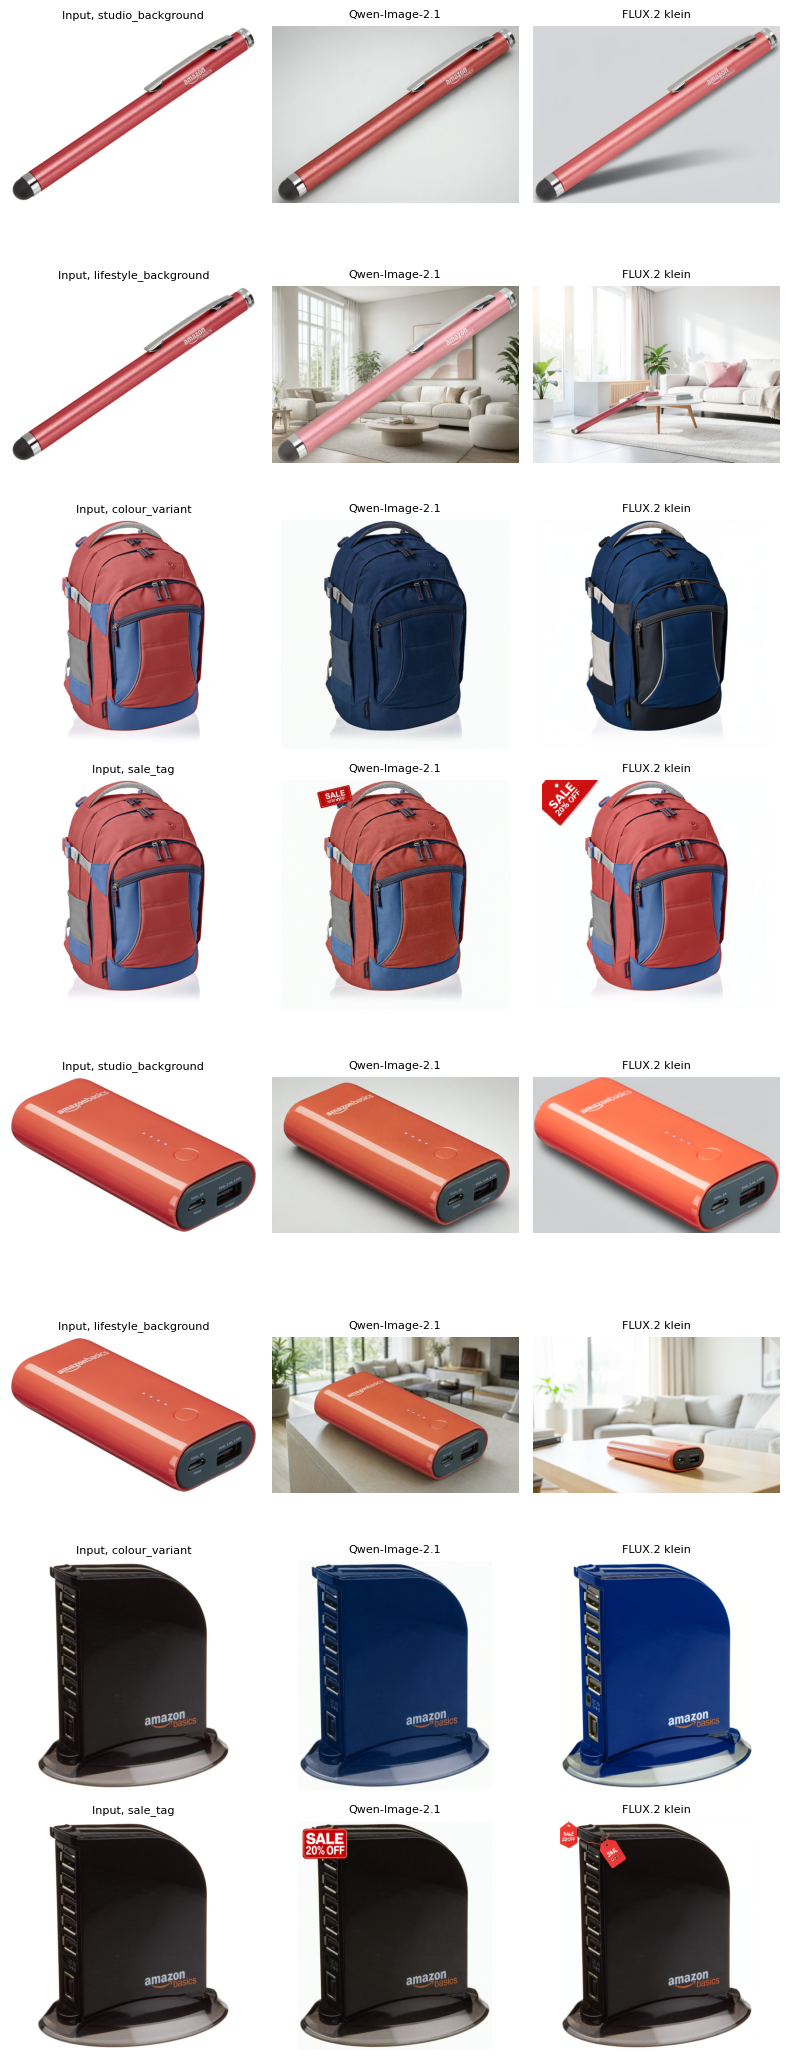

In [ ]:
# bar chart of the four metrics (mean and SD over seeds)
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, metric in zip(axes, METRICS):
    g = by_seed.groupby("system")[metric]
    ax.bar(g.mean().index, g.mean(), yerr=g.std(), capsize=4, color=["tab:orange", "tab:blue"])
    ax.set_title(f"{metric} (mean and SD, 3 seeds)", fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "fig_metrics.png", dpi=150)
plt.show()

# every edit (seed 0) next to its input photo
fig, axes = plt.subplots(len(edits), 3, figsize=(8, 2.6 * len(edits)))
for i, e in enumerate(edits.itertuples()):
    for j, (title, path) in enumerate([("Input", e.photo), (A, OUT / "qwen" / "seed0" / f"{e.edit}.png"), (B, OUT / "klein" / "seed0" / f"{e.edit}.png")]):
        axes[i][j].imshow(Image.open(path))
        axes[i][j].set_title(f"{title}, {e.task}" if j == 0 else title, fontsize=8)
        axes[i][j].axis("off")
fig.tight_layout()
fig.savefig(OUT / "fig_examples.jpg", dpi=120)
plt.show()

## My ratings
The assignment specification update of 26 October allows my own evaluation as user feedback. For each edit (seed 0) the input photo and the two edits are saved,
the edits as X and Y in a random order; the key goes in a separate file that I only open after rating. Question: would
I publish this edit on the product page? (1 = no, 5 = yes as it is). I also time how long it takes me to approve or
reject each edit (`seconds_to_check`); that is the review time in the cost table.

In [ ]:
# blind rating files: input photo plus both edits as X and Y in a random order
(OUT / "rating").mkdir(exist_ok=True)
key = []
for i, e in enumerate(edits.itertuples(), 1):
    swap = random.Random(i).random() < 0.5
    x, y = (B, A) if swap else (A, B)
    shutil.copy(e.photo, OUT / "rating" / f"item{i:02d}_input.png")
    for label, system in (("X", x), ("Y", y)):
        shutil.copy(OUT / ("qwen" if system == A else "klein") / "seed0" / f"{e.edit}.png", OUT / "rating" / f"item{i:02d}_{label}.png")
    key.append({"item": i, "edit": e.edit, "instruction": e.instruction, "X": x, "Y": y})
# the key and an empty ratings sheet; I filled in the sheet before opening the key
pd.DataFrame(key).to_csv(OUT / "rating" / "key.csv", index=False)
pd.DataFrame({"item": range(1, len(edits) + 1), "score_X": "", "score_Y": "", "seconds_to_check": ""}).to_csv(OUT / "rating" / "my_ratings.csv", index=False)

**Note:** this cell ran during the Kaggle run, before I did the blind ratings, so it prints "ratings not filled in yet". That is expected: the ratings had to come after the outputs were saved and before the key was opened. My ratings and their results are in the **last cell** of this notebook, which I ran on Google Colab afterwards.

In [ ]:
# run this after filling in rating/my_ratings.csv
r = pd.read_csv(OUT / "rating" / "my_ratings.csv").merge(pd.read_csv(OUT / "rating" / "key.csv"))
if r.score_X.notna().all():
    scores_r = pd.concat([r[["X", "score_X"]].set_axis(["system", "score"], axis=1), r[["Y", "score_Y"]].set_axis(["system", "score"], axis=1)])
    print(scores_r.groupby("system").score.agg(["mean", lambda s: (s >= 4).mean()]).set_axis(["mean score", "share rated 4 or 5"], axis=1))
    print(f"my review time: {r.seconds_to_check.mean():.1f} s per edit (rerun the cost cell to use it)")
else:
    print("ratings not filled in yet")

ratings not filled in yet


## Run record
Save the date, GPU, package versions, seeds and step counts to `run_info.json`, then zip the results folder for download.

In [ ]:
# record the run settings and zip the results folder
pd.Series({"date": time.ctime(), "gpu": torch.cuda.get_device_name(0), "torch": torch.__version__,
           "diffusers": __import__("diffusers").__version__, "transformers": __import__("transformers").__version__,
           "seeds": SEEDS, "edits": len(edits), "qwen steps": 40, "klein steps": 4}).to_json(OUT / "run_info.json")
shutil.make_archive("/kaggle/working/pair2_results", "zip", OUT)

'/kaggle/working/pair2_results.zip'

## My ratings: results
I ran this cell on Google Colab after the Kaggle run, once I had filled in `my_ratings.csv` without looking at `key.csv`. It joins my scores to the key, compares the two editors and recomputes the cost with my measured review time.

In [1]:
# my ratings, added after the Kaggle run (my_ratings.csv and key.csv from rating/, speed_cost.csv from the results)
import pandas as pd
from pathlib import Path
from scipy.stats import wilcoxon


# find an uploaded file anywhere under /content
def find(name):
    hits = sorted(Path("/content").rglob(name))
    if not hits:
        raise FileNotFoundError(f"{name} not found: upload it with the folder icon on the left and wait for the upload to finish")
    return hits[0]


# join my scores to the key so each score is linked to its editor
r = pd.read_csv(find("my_ratings.csv")).merge(pd.read_csv(find("key.csv")))
r = r.dropna(subset=["score_X", "score_Y"])
scores = pd.concat([r[["X", "score_X"]].set_axis(["system", "score"], axis=1),
                    r[["Y", "score_Y"]].set_axis(["system", "score"], axis=1)])
summary = scores.groupby("system").score.agg(["mean", lambda s: (s >= 4).mean()]).set_axis(["mean score", "share rated 4 or 5"], axis=1)
display(summary.round(2))

# paired comparison of my scores, item by item
wide = scores.assign(item=list(r.item) * 2).pivot(index="item", columns="system", values="score")
d = wide["Qwen-Image-2.1"] - wide["FLUX.2 klein"]
print(len(r), "items rated")
print("items where Qwen scored higher:", (d > 0).sum(), "| klein higher:", (d < 0).sum(), "| ties:", (d == 0).sum())
print("Wilcoxon p on scores:", round(wilcoxon(d).pvalue, 3) if (d != 0).any() else "all ties")

# cost again, with my measured review time instead of 60 s
secs = r.seconds_to_check.mean()
cost = pd.read_csv(find("speed_cost.csv"))
cost["review AUD per edit"] = secs / 3600 * 61.41
cost["saving AUD per month (2,000 edits)"] = (17.32 - cost["GPU AUD per edit"] - cost["review AUD per edit"]) * 2000
cost["share I would publish"] = cost.system.map(summary["share rated 4 or 5"])
cost["saving AUD per month (only edits I would publish)"] = cost["saving AUD per month (2,000 edits)"] * cost["share I would publish"]
print(f"my review time: {secs:.1f} s per edit")
display(cost.round(3))

summary.to_csv("user_ratings_summary.csv")
cost.to_csv("speed_cost_with_review.csv", index=False)

,mean score,share rated 4 or 5
system,,
FLUX.2 klein,3.50,0.50
Qwen-Image-2.1,4.12,0.62


8 items rated
items where Qwen scored higher: 5 | klein higher: 3 | ties: 0
Wilcoxon p on scores: 0.422
my review time: 17.5 s per edit


,system,seconds per edit,GPU energy Wh per edit (max),GPU AUD per edit,review AUD per edit,agency AUD per edit,"saving AUD per month (2,000 edits)",share I would publish,saving AUD per month (only edits I would publish)
0,FLUX.2 klein,26.897,0.523,0.007,0.299,17.32,34028.165,0.500,17014.082
1,Qwen-Image-2.1,114.677,2.230,0.032,0.299,17.32,33979.886,0.625,21237.429
